In [1]:
import os
import sys
import random
import numpy as np
import pandas as pd
import scanpy as sc
import torch
from PIL import Image

# ============ 路径配置 ============
# 找到 tutorial 目录：优先用当前工作目录；若不对则自动向上一级查找
def find_tutorial_dir():
    cwd = os.getcwd()
    # 如果当前目录下就有 tonsil_data，说明已经在 tutorial 里
    if os.path.isdir(os.path.join(cwd, 'tonsil_data')):
        return cwd
    # 否则看上一级
    parent = os.path.dirname(cwd)
    if os.path.isdir(os.path.join(parent, 'tonsil_data')):
        return parent
    # 再向上找一层（容错）
    grand = os.path.dirname(parent)
    if os.path.isdir(os.path.join(grand, 'tonsil_data')):
        return grand
    raise FileNotFoundError(
        "找不到 tonsil_data 目录，请把 example.ipynb 放在 tutorial/ 目录下，"
        "并确保 tutorial/tonsil_data/ 存在。"
    )

BASE_DIR = find_tutorial_dir()                 # .../miso-main/tutorial
DATA_DIR = os.path.join(BASE_DIR, 'tonsil_data')
MISO_DIR = os.path.dirname(BASE_DIR)           # .../miso-main

sys.path.insert(0, MISO_DIR)

print(f"[路径] BASE_DIR = {BASE_DIR}")
print(f"[路径] DATA_DIR = {DATA_DIR}")
print(f"[路径] MISO_DIR = {MISO_DIR}")

[路径] BASE_DIR = /home/graduates/XiaoYX/ISOGAM/miso-main/tutorial
[路径] DATA_DIR = /home/graduates/XiaoYX/ISOGAM/miso-main/tutorial/tonsil_data
[路径] MISO_DIR = /home/graduates/XiaoYX/ISOGAM/miso-main


In [2]:
from miso.hist_features import get_features
from miso.utils import preprocess
from miso import Miso

Image.MAX_IMAGE_PIXELS = None
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from collections import Counter

seed = 100
np.random.seed(seed)
torch.manual_seed(seed)
random.seed(seed)

if torch.cuda.is_available():
    device = 'cuda'
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print("CUDA is available. GPU:", torch.cuda.get_device_name(0))
else:
    device = 'cpu'
    print("CUDA is not available. Using CPU.")

CUDA is available. GPU: NVIDIA GeForce RTX 4090


In [3]:
im = Image.open(os.path.join(DATA_DIR, 'he-raw.tif'))
pixel_size_raw = 65 / 255.54640512302527
pixel_size = 0.5
rad = 55 / (2 * pixel_size_raw)

locs = pd.read_csv(os.path.join(DATA_DIR, 'locs.csv'), index_col=0)
locs.columns = [str(i) for i in range(1, 6)]

image_emb = get_features(im, locs, rad, pixel_size_raw, pixel_size,
                         pretrained=True, device=device)
np.save(os.path.join(DATA_DIR, 'image_emb.npy'), image_emb)
print(f"[特征] 已保存到 {os.path.join(DATA_DIR, 'image_emb.npy')}")

Scaling image
Preprocessing image
Adjusting margins


Extracting image features: 1/4:   0%|          | 0/4 [00:00<?, ?it/s]

Model loaded to device: cuda:0
Model loaded to device: cuda:0
Model loaded to device: cuda:0
Model loaded to device: cuda:0


Extracting image features: 2/4:   0%|          | 0/4 [00:00<?, ?it/s]

Model loaded to device: cuda:0
Model loaded to device: cuda:0
Model loaded to device: cuda:0
Model loaded to device: cuda:0


Extracting image features: 3/4:   0%|          | 0/4 [00:00<?, ?it/s]

Model loaded to device: cuda:0
Model loaded to device: cuda:0
Model loaded to device: cuda:0
Model loaded to device: cuda:0


Extracting image features: 4/4:   0%|          | 0/4 [00:00<?, ?it/s]

Model loaded to device: cuda:0
Model loaded to device: cuda:0
Model loaded to device: cuda:0
Model loaded to device: cuda:0
Smoothing embeddings
Adjusting weights...
1 sec
[特征] 已保存到 /home/graduates/XiaoYX/ISOGAM/miso-main/tutorial/tonsil_data/image_emb.npy


In [4]:
rna = sc.read(os.path.join(DATA_DIR, 'rna.h5ad'))
rna = preprocess(rna, modality='rna')

protein = sc.read(os.path.join(DATA_DIR, 'protein.h5ad'))
protein = preprocess(protein, modality='protein')

/home/graduates/anaconda3/envs/miso_env/lib/python3.7/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [5]:
model = Miso(
    [rna, protein, image_emb],
    ind_views='all',
    combs='all',
    sparse=False,
    device=device,
    learnable_weights=True,    # 创新点2：自适应注意力权重
    use_graph_encoder=True,    # 创新点1：图自编码器
    spatial_locs=locs,         # 创新点1：空间KNN图
    spatial_neighbors=6
)

[MISO] 空间KNN图构建完成，每spot连接最近 6 个空间邻居
Initialized learnable weights:
  rna: 1.0000
  protein: 1.0000
  image_emb: 1.0000


In [6]:
EMB_PATH = os.path.join(DATA_DIR, 'emb.npy')
if os.path.exists(EMB_PATH):
    model.emb = np.load(EMB_PATH)
    print(f"[ISOGAM] 已加载缓存 embedding：{EMB_PATH}，跳过训练。")
    print(f"[ISOGAM] 如需重新训练，请删除 {EMB_PATH} 后再运行。")
else:
    model.train()
    np.save(EMB_PATH, model.emb)
    print(f"[ISOGAM] 训练完成，embedding 已保存到 {EMB_PATH}。")

[ISOGAM] 已加载缓存 embedding：/home/graduates/XiaoYX/ISOGAM/miso-main/tutorial/tonsil_data/emb.npy，跳过训练。
[ISOGAM] 如需重新训练，请删除 /home/graduates/XiaoYX/ISOGAM/miso-main/tutorial/tonsil_data/emb.npy 后再运行。


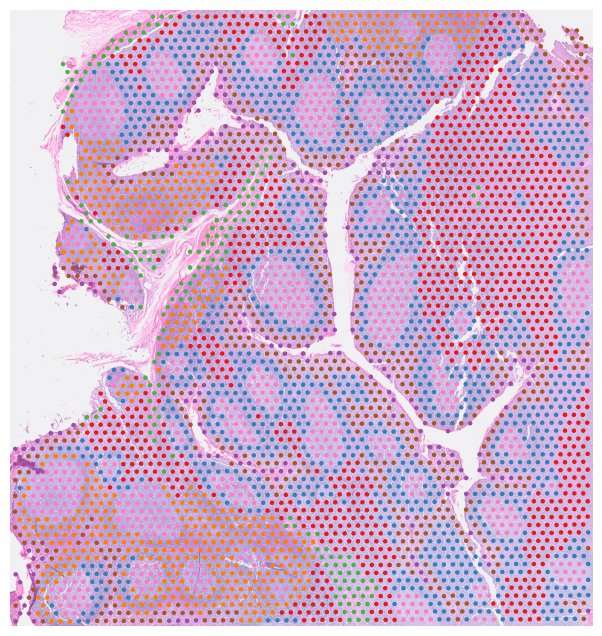

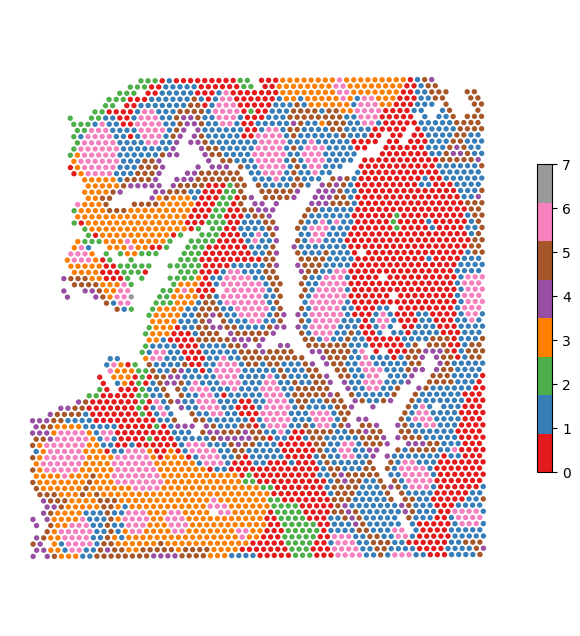

================== Clustering Metrics ==================
ICC (overall):  0.3006
RNA ICC:        0.2007
Protein ICC:    0.4974
Image ICC:      0.2036
Moran's I: 0.6303


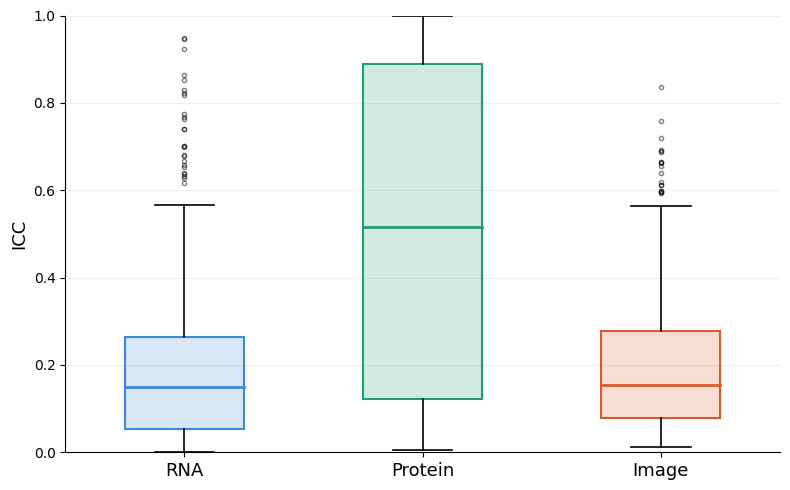

In [7]:
# ============ 聚类 ============
clusters = model.cluster(n_clusters=8, use_deep_graph_clustering=False)
clusters_smoothed = clusters.copy()
model.clusters = clusters_smoothed   # 供 ICC 计算使用

# ============ 颜色配置 ============
cluster_colors = [
    '#E41A1C', '#377EB8', '#4DAF4A', '#FF7F00', '#984EA3',
    '#A65628', '#F781BF', '#999999', '#FFFF33', '#00CED1',
    '#66C2A5', '#FC8D62', '#8DA0CB', '#E78AC3', '#A6D854'
]
import matplotlib.colors as mcolors
n_unique = len(np.unique(clusters_smoothed))
custom_cmap = mcolors.ListedColormap(cluster_colors[:n_unique])

# ============ 叠加组织图 ============
disp_scale = 0.1
im_lowres = np.array(im.resize(
    (int(im.width * disp_scale), int(im.height * disp_scale)), Image.LANCZOS
))

def plot_on_histology(clusters, locs, im, scale, s=10, cmap=None):
    locs = (locs * scale).round().astype('int')
    im   = im[(locs['4'].min()-10):(locs['4'].max()+10),
              (locs['5'].min()-10):(locs['5'].max()+10)]
    locs = locs - locs.min() + 10
    if cmap is None:
        cmap = mcolors.ListedColormap(
            [plt.cm.tab20(np.array(i)) for i in range(len(np.unique(clusters)))]
        )
    plt.imshow(im, alpha=0.7)
    plot = plt.scatter(x=locs['5'], y=locs['4'], c=clusters, cmap=cmap, s=s)
    plt.axis('off')
    return plot

plt.figure(figsize=(8, 8))
plot_on_histology(clusters_smoothed, locs, im_lowres, disp_scale, s=5, cmap=custom_cmap)
plt.savefig(os.path.join(DATA_DIR, 'clusters_on_histology.svg'), dpi=300, bbox_inches='tight')
plt.show()

# ============ 纯点图 ============
coords = locs[['4', '5']].values
plt.figure(figsize=(8, 8))
scatter = plt.scatter(coords[:, 1], coords[:, 0],
                      c=clusters_smoothed, cmap=custom_cmap, s=15, edgecolors='none')
plt.gca().invert_yaxis()
plt.axis('equal')
plt.axis('off')
plt.colorbar(scatter, shrink=0.5, ticks=range(n_unique))
plt.savefig(os.path.join(DATA_DIR, 'clusters_points.svg'), dpi=300, bbox_inches='tight')
plt.show()

# ============ ICC + Moran's I ============
icc_overall = model._calculate_icc()
icc_rna     = model._calculate_rna_icc()
icc_protein = model._calculate_protein_icc()
icc_image   = model._calculate_image_icc()

print("================== Clustering Metrics ==================")
print(f"ICC (overall):  {icc_overall:.4f}")
print(f"RNA ICC:        {icc_rna:.4f}")
print(f"Protein ICC:    {icc_protein:.4f}")
print(f"Image ICC:      {icc_image:.4f}")

def calculate_morans_i(clusters, locs, n_neighbors=6):
    coords = locs[['4', '5']].values
    n = len(clusters)
    tree = cKDTree(coords)
    _, indices = tree.query(coords, k=n_neighbors + 1)
    W = np.zeros((n, n))
    for i in range(n):
        W[i, indices[i, 1:]] = 1.0 / n_neighbors
    x = clusters.astype(float)
    x_dev = x - x.mean()
    W_sum = W.sum()
    den = x_dev @ x_dev
    if den < 1e-10:
        return 0.0, 0.0
    mi = (n / W_sum) * (x_dev @ W @ x_dev) / den
    return mi, 0.0   # 这里简化，如果只要 mi 可以这么写

morans_i, _ = calculate_morans_i(clusters_smoothed, locs)
print(f"Moran's I: {morans_i:.4f}")

# ============ ICC 箱型图 ============
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
box_colors = ['#378ADD', '#1D9E75', '#D85A30']
modality_names = ['RNA', 'Protein', 'Image']
icc_dists = [model.calculate_icc_distribution(i) for i in range(3)]
bp = ax.boxplot(icc_dists, patch_artist=True, widths=0.5,
                medianprops=dict(linewidth=2),
                whiskerprops=dict(linewidth=1.2),
                capprops=dict(linewidth=1.2),
                flierprops=dict(marker='o', markersize=3, alpha=0.5))
for patch, c in zip(bp['boxes'], box_colors):
    patch.set_facecolor(c + '33'); patch.set_edgecolor(c); patch.set_linewidth(1.5)
for median, c in zip(bp['medians'], box_colors):
    median.set_color(c)
ax.set_xticklabels(modality_names, fontsize=13)
ax.set_ylabel('ICC', fontsize=13)
ax.set_ylim(0, 1)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'icc_boxplot.svg'), dpi=300, bbox_inches='tight')
plt.show()